# Hof Lecture | Exploratory Data Analysis
**Solutions**

**Business question:** Which carrier needs attention, and what should we check first?

We inspect a shipment export, make justified changes and check how they affect the delivery report. By the end, you can identify data issues, explain a treatment choice and report a KPI together with its limitations.

Run the cells in order. The assigned changes are already applied. Each THINK section is followed by worked answers and explanations.

Each experiment has a fixed BEFORE reference. The later experiments use the reviewed version of the case so that each comparison can be run independently after setup. The original export is always preserved.


## The shipment case

This is an illustrative dataset, not real carrier performance. **One row should represent one shipment.** The raw export has **13 rows and 12 distinct shipment IDs** because one row is repeated exactly.

| Column | Meaning and units | First row |
|---|---|---|
| Shipment_ID | Shipment identifier | S001 |
| Carrier | Carrier label, with confirmed allowed values A and B | A |
| Delivery_Time_hrs | Recorded dispatch-to-delivery duration, hours | 10 |
| SLA_hrs | Maximum permitted duration, hours | 24 |
| Notes | Delivery comment, which may be blank | Delivered |

S001 took 10 hours against a 24-hour limit, so it was on time. We assume the durations use the same clock and time basis. A valid duration at or below the shipment's own SLA counts as on time. A missing or invalid duration leaves the outcome **unknown**. Shipment completeness is not measured, so this is **on-time delivery**, not OTIF.

A blank note does not mean there was no issue. No values are inferred from a clean reference dataset. No external files, downloads or uploads are needed.

For THINK, begin with the table or chart on the page. Explain one observation, then connect it to a business decision. No new formula is needed. Reasonable decisions can differ when supported by the evidence.


**Methods used here:** frequency counts, numeric summaries, a histogram, a boxplot, comparison of missing-value estimates, IQR screening and verification checks. The data have no dates or distances, so a time plot, interpolation or a distance-versus-duration analysis would need additional fields. The MCAR/MAR/MNAR labels describe possible recording mechanisms; the pattern of two gaps cannot establish which mechanism caused them.


## Provided functions
Run these setup cells once. The experiment cells below contain the parameters to change.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


In [2]:
def create_shipments():
    """Illustrative case: one row per shipment, plus one exact repeated row."""
    data = pd.DataFrame({
        "Shipment_ID": [f"S{i:03d}" for i in range(1, 13)],
        "Carrier": ["A", " a ", "A", "B", "B", "B", "B", "B", "A", "A", "B", "A"],
        "Delivery_Time_hrs": [10, 12, 14, 16, 18, 72, np.nan, -4, 8, 9, 20, 22],
        "SLA_hrs": [24, 24, 24, 24, 24, 24, 12, 12, 12, 12, 24, 24],
        "Notes": ["Delivered", "", "", "", "", "Customs hold", "Awaiting proof", "Timestamp error", "", "", "", ""]
    })
    return pd.concat([data.iloc[:2], data.iloc[[1]], data.iloc[2:]], ignore_index=True)


def peek(data):
    """Display blanks explicitly without overwriting the original notes."""
    shown = data.copy(deep=True)
    shown["Carrier"] = shown.Carrier.map(repr)
    shown["Notes"] = shown.Notes.replace("", "Not recorded")
    display(shown)


In [3]:
def quality_summary(data):
    time = pd.to_numeric(data.Delivery_Time_hrs, errors="coerce")
    return pd.Series({
        "Rows": len(data), "Distinct shipment IDs": data.Shipment_ID.nunique(),
        "Exact duplicate rows": int(data.duplicated().sum()),
        "Carrier labels": data.Carrier.nunique(),
        "Missing durations": int(time.isna().sum()),
        "Invalid negative durations": int((time < 0).sum())
    })


def discover(data, group_by_carrier=False):
    display(quality_summary(data).to_frame("Count"))
    if group_by_carrier:
        counts = data.groupby("Carrier", dropna=False).size()
        display(pd.DataFrame({"Carrier label as stored": [repr(x) for x in counts.index],
                              "Rows": counts.to_numpy()}))
        print("These are raw record counts. A repeated shipment is counted twice.")


def compare_quality(before, after):
    result = pd.DataFrame({"BEFORE": quality_summary(before), "AFTER": quality_summary(after)})
    result["CHANGE (AFTER - BEFORE)"] = result.AFTER - result.BEFORE
    display(result)


In [4]:
def repair_records(data, apply=False):
    """Case rule: confirmed A/B carrier list and exact repeated shipment rows."""
    result = data.copy(deep=True)
    if apply:
        result["Carrier"] = result.Carrier.str.strip().str.upper()
        if not result.Carrier.isin(["A", "B"]).all():
            raise ValueError("Unrecognized carrier: review the mapping first.")
        result = result.drop_duplicates().reset_index(drop=True)
        if result.Shipment_ID.duplicated().any():
            raise ValueError("Conflicting rows share an ID. Review them before continuing.")
    return result


def flag_invalid(data, apply=False):
    """Preserve the issue flag. Leave the shipment in the dataset."""
    result = data.copy(deep=True)
    time = pd.to_numeric(result.Delivery_Time_hrs, errors="raise")
    result["Time_review"] = np.where(time.isna(), "Missing duration", "Recorded")
    result.loc[time < 0, "Time_review"] = "Invalid duration: check timestamps"
    if apply:
        result.loc[time < 0, "Delivery_Time_hrs"] = np.nan
    return result


In [5]:
def service_rows(data):
    """Unknown or invalid times do not count as on time or late."""
    result = data.copy(deep=True)
    time = pd.to_numeric(result.Delivery_Time_hrs, errors="coerce")
    valid = time.notna() & np.isfinite(time) & (time >= 0) & (result.SLA_hrs > 0)
    result["Service_status"] = "Unknown"
    result.loc[valid & (time <= result.SLA_hrs), "Service_status"] = "On time"
    result.loc[valid & (time > result.SLA_hrs), "Service_status"] = "Late"
    return result


def service_summary(data):
    result = service_rows(data)
    known = result.Service_status != "Unknown"
    on_time = int((result.Service_status == "On time").sum())
    return pd.Series({"Shipments": len(result), "Known outcomes": int(known.sum()),
        "Unknown outcomes": int((~known).sum()), "On-time shipments": on_time,
        "On-time rate among known (%)": 100 * on_time / known.sum() if known.any() else np.nan,
        "Average recorded duration (hours)": result.loc[known, "Delivery_Time_hrs"].mean()})


In [6]:
def plot_times(data, title):
    result = service_rows(data)
    known = result[result.Service_status != "Unknown"]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(known.Shipment_ID, known.Delivery_Time_hrs, color="#5B9BD5", label="Recorded duration")
    ax.plot(known.Shipment_ID, known.SLA_hrs, "o--", color="#ED7D31", label="SLA")
    ax.set(title=title, xlabel="Shipment ID", ylabel="Hours")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(); fig.tight_layout(); plt.show()
    print("Unknown outcomes excluded from the chart:", int((result.Service_status == "Unknown").sum()))


def cap_times(data, cap_hours=None):
    """Make a separate comparison copy; do not alter recorded evidence."""
    result = data.copy(deep=True)
    if cap_hours is not None:
        if not np.isfinite(cap_hours) or cap_hours < 0:
            raise ValueError("Use a nonnegative finite cap or None.")
        result["Delivery_Time_hrs"] = result.Delivery_Time_hrs.clip(upper=cap_hours)
    return result


def compare_service(before, after):
    table = pd.DataFrame({"BEFORE": service_summary(before), "AFTER": service_summary(after)})
    table["CHANGE (AFTER - BEFORE)"] = table.AFTER - table.BEFORE
    display(table.round(2))
    print("Rate changes are percentage points. Duration changes are hours.")


In [7]:
def report_service(data, show_unknown=False):
    result = service_rows(data)
    summary = service_summary(result)
    if not show_unknown:
        print(f"On-time rate among known outcomes: {summary['On-time rate among known (%)']:.0f}%")
        print("This short report omits counts and coverage.")
        return
    print(f"On time: {int(summary['On-time shipments'])} of {int(summary['Known outcomes'])} known outcomes "
          f"({summary['On-time rate among known (%)']:.0f}%).")
    print(f"Unknown outcomes: {int(summary['Unknown outcomes'])} of {len(result)} shipments.")
    rows = []
    for carrier, group in result.groupby("Carrier"):
        known = int((group.Service_status != "Unknown").sum())
        on_time = int((group.Service_status == "On time").sum())
        unknown = int((group.Service_status == "Unknown").sum())
        rows.append([carrier, len(group), known, on_time, unknown, 100 * on_time / known if known else np.nan])
    display(pd.DataFrame(rows, columns=["Carrier", "Shipments", "Known", "On time", "Unknown", "Known-outcome rate (%)"]))


def verify_reviewed(raw, reviewed):
    status = service_rows(reviewed)
    checks = {
        "One row per shipment ID": reviewed.Shipment_ID.is_unique,
        "One confirmed repeated row removed": len(raw) - len(reviewed) == 1,
        "Carrier labels match A/B list": reviewed.Carrier.isin(["A", "B"]).all(),
        "Recorded durations are nonnegative": reviewed.Delivery_Time_hrs.dropna().ge(0).all(),
        "SLA values are positive and present": reviewed.SLA_hrs.notna().all() and reviewed.SLA_hrs.gt(0).all(),
        "Confirmed 72-hour delay retained": reviewed.loc[reviewed.Shipment_ID == "S006", "Delivery_Time_hrs"].eq(72).all()
    }
    display(pd.DataFrame({"Check": list(checks), "Result": ["PASS" if x else "REVIEW" for x in checks.values()]}))
    print("Follow up these outcomes before issuing a complete service score:")
    display(status.loc[status.Service_status == "Unknown", ["Shipment_ID", "Carrier", "Time_review"]])


In [8]:
def valid_times(data):
    rows = service_rows(data)
    return rows.loc[rows.Service_status != "Unknown", "Delivery_Time_hrs"]


def describe_times(data):
    values = valid_times(data)
    display(pd.DataFrame({"Measure": ["Valid durations", "Mean (hours)", "Median (hours)", "Minimum (hours)", "Maximum (hours)"],
        "Value": [len(values), values.mean(), values.median(), values.min(), values.max()]}).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].hist(values, bins=[0, 12, 24, 36, 48, 60, 72, 84], color="#5B9BD5", edgecolor="white")
    axes[0].set(title="Distribution of recorded durations", xlabel="Delivery duration (hours)", ylabel="Shipment count")
    axes[1].boxplot(values)
    axes[1].set(title="Median, spread and unusual durations", ylabel="Delivery duration (hours)", xticks=[1], xticklabels=["Reviewed deliveries"])
    fig.tight_layout(); plt.show()
    print("Missing/invalid durations are excluded from these summaries, not removed from the dataset.")


In [9]:
def imputation_copy(data, method="keep"):
    """Estimate in a separate copy. Never treat estimates as recovered evidence."""
    if method not in ["keep", "mean", "median", "group_median"]:
        raise ValueError("Choose keep, mean, median or group_median.")
    result = data.copy(deep=True)
    missing = result.Delivery_Time_hrs.isna()
    result["Was_imputed"] = False
    if method == "mean":
        result["Delivery_Time_hrs"] = result.Delivery_Time_hrs.fillna(result.Delivery_Time_hrs.mean())
    elif method == "median":
        result["Delivery_Time_hrs"] = result.Delivery_Time_hrs.fillna(result.Delivery_Time_hrs.median())
    elif method == "group_median":
        group_values = result.groupby("Carrier").Delivery_Time_hrs.transform("median")
        result["Delivery_Time_hrs"] = result.Delivery_Time_hrs.fillna(group_values)
    result["Was_imputed"] = missing & result.Delivery_Time_hrs.notna()
    return result


def compare_imputation(data, method="keep"):
    trial = imputation_copy(data, method)
    before = service_summary(data)
    hypothetical = service_summary(trial)
    display(pd.DataFrame({"Measure": ["Recorded outcomes", "Estimated durations added", "Values in duration calculation", "Average analysis duration (hours)", "Hypothetical on-time rate using filled values (%)"],
        "BEFORE (keep unknown)": [before["Known outcomes"], 0, before["Known outcomes"], before["Average recorded duration (hours)"], before["On-time rate among known (%)"]],
        "AFTER (" + method + ")": [before["Known outcomes"], int(trial.Was_imputed.sum()), hypothetical["Known outcomes"], hypothetical["Average recorded duration (hours)"], hypothetical["On-time rate among known (%)"]]}).round(2))
    display(trial.loc[data.Delivery_Time_hrs.isna(), ["Shipment_ID", "Carrier", "SLA_hrs", "Delivery_Time_hrs", "Was_imputed"]])
    print("Estimates are for comparison only. Recorded outcomes and the official reviewed dataset are unchanged.")
    return trial


In [10]:
def show_iqr_review(data):
    values = valid_times(data)
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    display(pd.DataFrame({"Measure": ["Q1 (hours)", "Q3 (hours)", "IQR (hours)", "Lower fence (hours)", "Upper fence (hours)"],
                          "Value": [q1, q3, iqr, lower, upper]}))
    unusual = data.Delivery_Time_hrs.notna() & ((data.Delivery_Time_hrs < lower) | (data.Delivery_Time_hrs > upper))
    display(data.loc[unusual, ["Shipment_ID", "Carrier", "Delivery_Time_hrs", "SLA_hrs", "Notes"]])
    print("An IQR flag requests investigation. It does not prove an error or authorize deletion.")
    return {"lower": float(lower), "upper": float(upper), "flagged_ids": data.loc[unusual, "Shipment_ID"].tolist()}


## Baseline
Read the first rows and the quality summary. The original export remains unchanged throughout the exercises.

In [11]:
raw_data = create_shipments()
records_reference = repair_records(raw_data, apply=True)
reviewed_reference = flag_invalid(records_reference, apply=True)
peek(raw_data.head(3))
discover(raw_data)  # <-- OBSERVE OUTPUT


,Shipment_ID,Carrier,Delivery_Time_hrs,SLA_hrs,Notes
0,S001,'A',10.0,24,Delivered
1,S002,' a ',12.0,24,Not recorded
2,S002,' a ',12.0,24,Not recorded


,Count
Rows,13
Distinct shipment IDs,12
Exact duplicate rows,1
Carrier labels,3
Missing durations,1
Invalid negative durations,1


**THINK:** What does the first row mean? What does the repeated S002 tell you to check before counting shipments?

**Answer:** S001 is a carrier A shipment recorded at 10 hours against a 24-hour SLA, so it is on time. The repeated S002 means raw row counts may overstate shipment counts. Confirm the intended row definition and the duplicate record before removing it.

### The delivery-time pattern

Read the summary and the two plots below. The summary uses one record per shipment and only valid recorded durations. The histogram shows where durations are concentrated. The boxplot shows the middle values and marks unusual observations.


,Measure,Value
0,Valid durations,10.0
1,Mean (hours),20.1
2,Median (hours),15.0
3,Minimum (hours),8.0
4,Maximum (hours),72.0


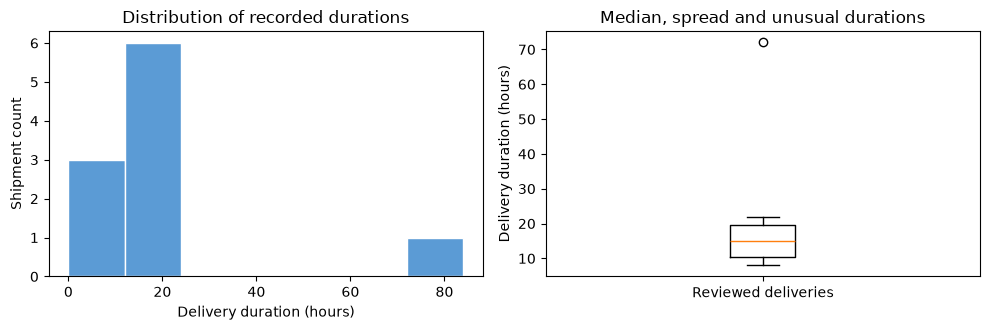

Missing/invalid durations are excluded from these summaries, not removed from the dataset.


In [12]:
describe_times(reviewed_reference)  # <-- OBSERVE OUTPUT


**THINK — summaries and plots**

1. The displayed mean and median differ. Which duration in the plot might help explain that gap?
2. Would reporting only one average tell the delivery manager the full story? Name something else visible in the plots that matters.
3. Which shipment would you investigate, and what would you want to know about it?

**Answers and explanations**

1. The mean is 20.1 hours and the median is 15 hours. The 72-hour shipment pulls the mean upward, while the median reflects the middle of the ten valid durations.
2. No. Most recorded durations lie between 8 and 22 hours, while one is 72 hours. An average alone hides that long delay. The two unknown outcomes also remain outside these plots and need separate reporting.
3. Investigate S006. Ask whether its long duration reflects a genuine customs disruption or a recording problem, using its timestamps and event records. Its note provides context, not a reason to discard the event.


## Experiment 1 — SEE: inspect the carrier labels

**Business question:** Can we trust the raw carrier counts?

**BEFORE:** The overview shows all 13 raw rows together.

**CHANGE:** Set GROUP_BY_CARRIER from False to True to display counts for each stored carrier label. This changes the view, not the records.

**AFTER:** Read the label counts. Quotation marks make spaces in labels visible.

In [13]:
GROUP_BY_CARRIER = True  # <-- CHANGE HERE: False -> True
discover(raw_data, group_by_carrier=GROUP_BY_CARRIER)  # <-- OBSERVE OUTPUT


,Count
Rows,13
Distinct shipment IDs,12
Exact duplicate rows,1
Carrier labels,3
Missing durations,1
Invalid negative durations,1


,Carrier label as stored,Rows
0,' a ',2
1,'A',5
2,'B',6


These are raw record counts. A repeated shipment is counted twice.


**THINK**

1. **Notice:** Which labels appear when you group the raw records? Do you see two labels that might refer to the same carrier?

2. **Explain:** The counts include a repeated shipment. Why could that give a misleading picture of how much work a carrier handled?

3. **Decide:** Before combining the labels or removing a record, what would you ask the operations team to confirm?

**Answers and explanations**

1. The stored labels are A, " a " and B. Their raw row counts are 5, 2 and 6. A and " a " may refer to the same carrier, which the case's confirmed carrier list supports.

2. The repeated S002 row counts the same shipment twice. Carrier row counts then describe export records rather than distinct shipments and can distort workload shares.

3. Confirm that A and " a " identify the same carrier and that each row should represent a whole shipment. Confirm that S002 is an exact repeated export row rather than a legitimate separate event. A repeated ID alone is not enough to delete a record.

## Experiment 2 — TREAT: labels and the repeated record

**Business question:** What should change when we correct the shipment records?

**BEFORE:** The raw export contains 13 rows, three stored carrier labels and one exact repeated row.

**CHANGE:** Set FIX_RECORDS from False to True. Apply the confirmed carrier mapping and remove the exact repeated row. These changes are grouped because both establish a consistent shipment record.

**AFTER:** Read the quality comparison and the carrier counts. Delivery times are unchanged.

In [14]:
FIX_RECORDS = True  # <-- CHANGE HERE: False -> True
records_result = repair_records(raw_data, apply=FIX_RECORDS)
compare_quality(raw_data, records_result)  # <-- OBSERVE OUTPUT
discover(records_result, group_by_carrier=True)


,BEFORE,AFTER,CHANGE (AFTER - BEFORE)
Rows,13,12,-1
Distinct shipment IDs,12,12,0
Exact duplicate rows,1,0,-1
Carrier labels,3,2,-1
Missing durations,1,1,0
Invalid negative durations,1,1,0


,Count
Rows,12
Distinct shipment IDs,12
Exact duplicate rows,0
Carrier labels,2
Missing durations,1
Invalid negative durations,1


,Carrier label as stored,Rows
0,'A',6
1,'B',6


These are raw record counts. A repeated shipment is counted twice.


**THINK**

1. **Notice:** How do the row count, duplicate count and number of carrier labels change?

2. **Explain:** Have these edits made the deliveries faster, or changed how the export represents them? Use a displayed count to explain.

3. **Decide:** If two records had the same ID but different delivery times, would you apply the same removal rule? What would you investigate first?

**Answers and explanations**

1. Rows fall from 13 to 12, exact duplicate rows fall from 1 to 0 and carrier labels fall from 3 to 2. After correction, A and B each have six shipments.

2. The edits correct the representation of shipments. They do not change actual delivery performance: the same 12 shipments and their recorded times remain. Removing one repeated row prevents double counting.

3. No. Different times could represent a correction, a separate event or an error. Inspect event definitions and the authoritative delivery record before deciding which value to use. The helper stops if conflicting records remain under the same shipment ID.

## Experiment 3 — TREAT: invalid and missing durations

**Business question:** What can we say when a delivery duration is unknown?

**BEFORE:** Use the version with carrier labels and the exact duplicate already corrected. One duration is blank and another is -4 hours.

**CHANGE:** Set FLAG_INVALID from False to True. Mark the negative duration for follow-up and replace its unusable numeric value with a missing value. Retain the shipment and its issue flag.

**AFTER:** Read the missing/invalid counts and the rows for S007 and S008. Blank notes remain blank in the underlying data.

This section has two parts: flag the unusable value first, then compare estimates in a separate copy.


In [15]:
FLAG_INVALID = True  # <-- CHANGE HERE: False -> True
missing_result = flag_invalid(records_reference, apply=FLAG_INVALID)
compare_quality(records_reference, missing_result)  # <-- OBSERVE OUTPUT
display(missing_result.loc[missing_result.Shipment_ID.isin(["S007", "S008"])])


,BEFORE,AFTER,CHANGE (AFTER - BEFORE)
Rows,12,12,0
Distinct shipment IDs,12,12,0
Exact duplicate rows,0,0,0
Carrier labels,2,2,0
Missing durations,1,2,1
Invalid negative durations,1,0,-1


,Shipment_ID,Carrier,Delivery_Time_hrs,SLA_hrs,Notes,Time_review
6,S007,B,NaN,12,Awaiting proof,Missing duration
7,S008,B,NaN,12,Timestamp error,Invalid duration: check timestamps


**THINK**

1. **Notice:** After flagging the negative duration, why do you see more missing durations but fewer invalid numeric durations?

2. **Explain:** Would filling both missing durations with the typical value of 15 hours tell us whether these shipments were really late against their 12-hour SLAs?

3. **Decide:** Which record or system would you check to establish their delivery outcomes? Explain what evidence you need.

**Answers and explanations**

1. Missing durations rise from one to two because the invalid -4 value becomes missing. Negative numeric durations fall from one to zero. Both shipments remain in the data, with separate reasons for follow-up. This is a clearer description of uncertainty, not a new operational failure.

2. No. Fifteen hours is the median of the ten valid durations, not recovered evidence about S007 or S008. Filling both with 15 would classify both as late against 12-hour SLAs without confirming what actually happened.

3. Request dispatch and delivery timestamps or a carrier proof-of-delivery record, and check their clock/time-zone basis. Use those records to reconstruct the duration and compare it with the shipment's SLA. An empty note cannot establish an on-time outcome.

### Missing-value methods: a comparison copy

### Possible reasons for the gaps

| Term | Meaning | A possible example |
|---|---|---|
| MCAR: missing completely at random | Missingness does not depend on recorded or unrecorded values. | Random upload failure unrelated to the shipment. |
| MAR: missing at random | Recorded fields explain missingness, with no remaining dependence on the unrecorded value. | A warehouse omits more weights regardless of actual weight within that warehouse. |
| MNAR: missing not at random | Missingness still depends on the unrecorded value itself. | Very late deliveries are less likely to be recorded. |

These are mechanisms to investigate. Two gaps for the same carrier do not establish which mechanism applies.

**BEFORE:** Keep the two unconfirmed durations unknown. Ten outcomes are recorded. **CHANGE:** Set IMPUTATION_METHOD from "keep" to "median" and rerun. Then try "mean" and "group_median" one at a time. Each method creates estimates in a separate copy. **AFTER:** Compare the replacement values and the hypothetical rate shown below. The reviewed dataset remains unchanged.

- **Mean:** use the average of valid durations.
- **Median:** use the middle of the valid durations.
- **Group median:** use valid durations for the same carrier.

A mode can replace a category only when that assumption fits the analysis. Filling blank notes with the common note would not establish what happened. Time interpolation needs a meaningful ordered time series, which these independent shipment records do not provide.


In [16]:
IMPUTATION_METHOD = "median"  # <-- CHANGE HERE: "keep" -> "median"; then try "mean" or "group_median"
imputation_result = compare_imputation(reviewed_reference, IMPUTATION_METHOD)  # <-- OBSERVE OUTPUT


,Measure,BEFORE (keep unknown),AFTER (median)
0,Recorded outcomes,10.0,10.00
1,Estimated durations added,0.0,2.00
2,Values in duration calculation,10.0,12.00
3,Average analysis duration (hours),20.1,19.25
4,Hypothetical on-time rate using filled values (%),90.0,75.00


,Shipment_ID,Carrier,SLA_hrs,Delivery_Time_hrs,Was_imputed
6,S007,B,12,15.0,True
7,S008,B,12,15.0,True


Estimates are for comparison only. Recorded outcomes and the official reviewed dataset are unchanged.


**THINK — choosing a missing-value method**

1. After choosing "median", what values appear for S007 and S008? How many delivery outcomes were actually recovered?
2. Why can an estimate change the hypothetical on-time percentage without telling us what happened to the shipments?
3. Both gaps belong to B. What would you ask about B's recording process before choosing how to handle them?

**Answers and explanations**

1. Both estimates are 15 hours and both carry Was_imputed=True. No actual delivery outcome was recovered: there are still only ten recorded outcomes. The analysis copy now contains twelve numeric durations and has a mean of 19.25 hours.
2. Both estimates exceed the shipments' 12-hour SLAs, so the hypothetical rate using filled values becomes 9 of 12, or 75%, instead of 9 of 10 recorded outcomes, or 90%. That classification follows from the replacement assumption, not new delivery evidence. The original 90% known-outcome report and its two unknowns remain unchanged.
3. Ask whether a system outage affected B, whether missing times relate to a recorded characteristic such as warehouse, or whether long delays were less likely to be entered. These suggest different mechanisms to investigate. They do not prove MCAR, MAR or MNAR from two gaps alone.

**Other method results:** The mean fills both with 20.1 hours. Carrier B's group median fills both with 19 hours. All three choices classify the estimates as late against a 12-hour SLA in this example, so all give a hypothetical 75% rate. Matching classifications do not confirm that any estimate equals the actual missing durations.


### IQR screening before the reporting comparison

**BEFORE:** The reviewed data contain ten valid durations. **CHANGE:** Run the IQR screening function to identify unusually high or low values. This changes the information displayed, not the data. **AFTER:** Read the printed fences and the flagged record. The function supplies the calculations; focus on what to investigate.


In [17]:
iqr_review = show_iqr_review(reviewed_reference)  # <-- OBSERVE OUTPUT


,Measure,Value
0,Q1 (hours),10.5
1,Q3 (hours),19.5
2,IQR (hours),9.0
3,Lower fence (hours),-3.0
4,Upper fence (hours),33.0


,Shipment_ID,Carrier,Delivery_Time_hrs,SLA_hrs,Notes
5,S006,B,72.0,24,Customs hold


An IQR flag requests investigation. It does not prove an error or authorize deletion.


**THINK — IQR screening**

1. Which shipment is flagged, and what do its duration and note tell you?
2. Does being outside the IQR fence justify deleting it from the carrier report?
3. What delivery evidence would you check before changing its recorded duration?

**Answers and explanations**

1. S006 is flagged at 72 hours, above the 33-hour upper fence. Its note records a customs hold. Q1 is 10.5 and Q3 is 19.5 hours, giving an IQR of 9 hours.
2. No. The rule identifies a value that differs from the central group. A confirmed delay still belongs in the service report. The -3-hour lower fence also does not make negative durations operationally valid; the business rule remains nonnegative recorded duration.
3. Check dispatch and arrival timestamps, proof of delivery and the customs event record. Correct an actual recording error when supported by evidence, while retaining a confirmed operational disruption.


## Experiment 4 — COMPARE: the long customs delay

**Business question:** Does capping a long delay improve the delivery, or only the report?

**BEFORE:** The reviewed dataset retains S006 at 72 hours against a 24-hour SLA. Ten durations are valid and two outcomes are unknown.

**CHANGE:** Set CAP_HOURS from None to 24. Create a separate capped copy for comparison. Keep reviewed_reference unchanged as the evidence-based version.

**AFTER:** Read the BEFORE / AFTER table and chart. This is a reporting sensitivity test, not a recommended cleaning rule.

,BEFORE,AFTER,CHANGE (AFTER - BEFORE)
Shipments,12.0,12.0,0.0
Known outcomes,10.0,10.0,0.0
Unknown outcomes,2.0,2.0,0.0
On-time shipments,9.0,10.0,1.0
On-time rate among known (%),90.0,100.0,10.0
Average recorded duration (hours),20.1,15.3,-4.8


Rate changes are percentage points. Duration changes are hours.


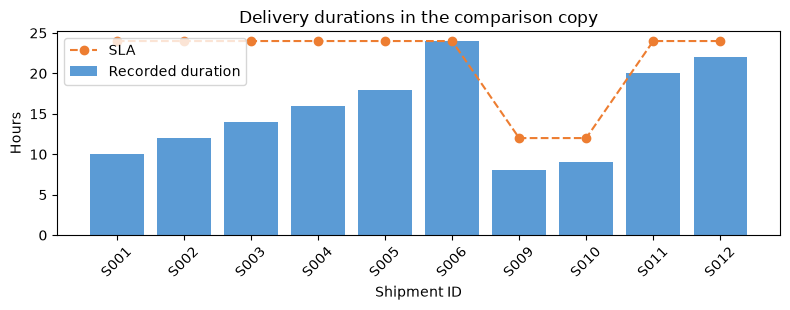

Unknown outcomes excluded from the chart: 2


In [18]:
CAP_HOURS = 24  # <-- CHANGE HERE: None -> 24 hours
capped_result = cap_times(reviewed_reference, cap_hours=CAP_HOURS)
compare_service(reviewed_reference, capped_result)  # <-- OBSERVE OUTPUT
plot_times(capped_result, "Delivery durations in the comparison copy")


**THINK**

1. **Notice:** What happens to average duration and the on-time rate among known outcomes when the cap is applied?

2. **Explain:** S006 was held in customs and actually took 72 hours. Why is the improved on-time rate in the capped copy misleading?

3. **Decide:** Which version would you use for the delivery report, and what would you ask the operations team to investigate?

**Answers and explanations**

1. Average recorded duration falls from 20.1 to 15.3 hours. On-time shipments rise from 9 of 10 to 10 of 10, so the known-outcome rate rises from 90% to 100%, a change of +10 percentage points. The two unknown outcomes remain unknown.

2. The cap rewrites S006 from 72 to 24 hours, making it meet a 24-hour SLA in the report. No delivery happened faster. The customs disruption disappears from the reported late count even though it was a real event.

3. Use the reviewed dataset with the 72-hour event preserved. Ask what caused the customs hold and whether a practical change could reduce that disruption. The capped copy is useful only for showing how a data choice changes the KPI.

## Experiment 5 — VERIFY: a report with coverage

**Business question:** Is a percentage enough to decide which carrier needs attention?

**BEFORE:** Use the reviewed, uncapped dataset. The short report shows only a known-outcome on-time percentage.

**CHANGE:** Set SHOW_UNKNOWN from False to True. Add counts, unknown outcomes and a carrier breakdown to the report. This changes reporting detail, not the underlying data.

**AFTER:** Read the total and carrier-level coverage, then the verification checks. PASS checks do not resolve the two unknown outcomes.

In [19]:
SHOW_UNKNOWN = True  # <-- CHANGE HERE: False -> True
report_service(reviewed_reference, show_unknown=SHOW_UNKNOWN)  # <-- OBSERVE OUTPUT
verify_reviewed(raw_data, reviewed_reference)


On time: 9 of 10 known outcomes (90%).
Unknown outcomes: 2 of 12 shipments.


,Carrier,Shipments,Known,On time,Unknown,Known-outcome rate (%)
0,A,6,6,6,0,100.0
1,B,6,4,3,2,75.0


,Check,Result
0,One row per shipment ID,PASS
1,One confirmed repeated row removed,PASS
2,Carrier labels match A/B list,PASS
3,Recorded durations are nonnegative,PASS
4,SLA values are positive and present,PASS
5,Confirmed 72-hour delay retained,PASS


Follow up these outcomes before issuing a complete service score:


,Shipment_ID,Carrier,Time_review
6,S007,B,Missing duration
7,S008,B,Invalid duration: check timestamps


**THINK**

1. **Notice:** The known-outcome rate is 90%. How many outcomes does it cover, and how many remain unknown? What does the carrier breakdown add?

2. **Explain:** Carrier A shows 100% and carrier B 75% among known outcomes. Why is that not enough to conclude that B causes worse delivery performance?

3. **Decide:** Write a short message for the delivery manager: one finding, one limitation and one next action.

**Answers and explanations**

1. Nine of ten known outcomes were on time, while two of twelve total outcomes remain unknown. A has six known, on-time outcomes. B has four known outcomes: three on time and one late, plus two unknown outcomes.

2. The groups are very small, their coverage differs and both unknowns belong to B. Routes and SLA requirements can also differ. The recorded late event involved a customs hold. The comparison identifies questions to investigate, not proof that the carrier caused the difference.

3. Example: "Nine of ten shipments with valid times were on time. Two outcomes, both for B, are still unknown. Obtain their delivery records and review the customs hold before making a carrier decision." Other messages are reasonable when they report both evidence and limitations.

## Final decision note

Use one result from the case to explain what you would tell the delivery manager. Include a finding, what remains unknown and a next action. A useful report can have unresolved gaps when it discloses them clearly. A complete, unqualified service score needs those gaps resolved.

**Answer:** The reviewed data contain 12 shipments, with 9 of 10 known outcomes on time and 2 unknown outcomes. The 72-hour customs delay remains part of the service evidence. Follow up the missing delivery records and review the customs event before judging carrier performance. Changing a data value can change a KPI without improving the operation.